# 05 — Extracción de Características
## Pipeline CAD-TBX11K | Diagnóstico Asistido por Computador en Tuberculosis

Este notebook construye la **matriz de características** que servirá como entrada a
los modelos de machine learning. Cada radiografía es convertida en un vector numérico
de **4199 características** agrupadas en doce grupos.

### Grupos de características

| Grupo | Qué captura | Features |
|----------------------|-------------------------------------------|:--------:|
| Intensidad global | brillo, variabilidad, rango dinámico, entropía | 4 |
| Intensidad regional | las mismas 4 métricas en 6 zonas anatómicas | 24 |
| GLCM | relación entre píxeles vecinos — textura del tejido | 10 |
| LBP | micro-patrones locales — bordes y transiciones | 26 |
| HOG | gradientes orientados — forma y estructura | 1764 |
| Gabor | energía de textura por frecuencia y orientación | 32 |
| PHOG | HOG piramidal — distribución espacial de orientaciones | 1440 |
| Estadística avanzada global/regional | distribución, asimetría y dispersión de intensidades | 77 |
| GLCM multiescala/regional | textura a distintas escalas y regiones | 270 |
| LBP multiescala | microtexturas a diferentes escalas | 28 |
| Asimetría bilateral | diferencias entre ambos hemitórax | 12 |
| GIST | estructura y contexto global de la imagen | 512 |
| **Total** | | **4199** |

### Pipeline por imagen

```
imagen → preprocess()
       → características base
          ├─ intensidad global/regional
          ├─ GLCM
          ├─ LBP
          ├─ HOG
          ├─ Gabor
          └─ PHOG
       → características ampliadas
          ├─ estadística avanzada
          ├─ GLCM multiescala/regional
          ├─ LBP multiescala
          ├─ asimetría bilateral
          └─ GIST
       → fila del CSV
```

La ampliación se evalúa posteriormente contra el conjunto base de **3300 features**
para determinar si aporta capacidad discriminativa adicional entre `health`, `sick` y `tb`.


## 0. Configuración del entorno

In [11]:
# Se configura el path del proyecto y se importan las funciones del framework.

import sys, os, warnings
warnings.filterwarnings('ignore')

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import numpy as np
import pandas as pd

from src.data import download_dataset, get_data_root, build_base_dataframe, LABEL_MAP

# Configuración central del pipeline: definida una sola vez en src/config.py
from src.config import N_MODELO
from src.features import (
    verify_extractors,        # Verifica el número correcto de features por extractor
    extract_all_features,     # Extracción masiva sobre el DataFrame base
    get_feature_groups,       # Clasifica columnas por grupo de extractor
    print_feature_summary,    # Resumen de integridad del DataFrame de features
    REGIONS, GLCM_PROPS,
    LBP_P, LBP_R, HOG_PIXELS_PER_CELL,
    ADVANCED_PERCENTILES, GLCM_DISTANCES_MS, LBP_EXTRA_SCALES,
    GIST_FREQUENCIES, GIST_ORIENTATIONS, GIST_GRID,
)
from src.visualization import (
    set_publication_style,
    plot_glcm_distributions,
    plot_lbp_histograms,
    plot_feature_summary_table,
)


from pathlib import Path
OUTPUT_CSV = Path('..') / 'data' / 'features_tbx11k.csv'

set_publication_style()
print('Entorno configurado correctamente.')

Entorno configurado correctamente.


## 1. Carga del DataFrame base

In [12]:
# Se carga el DataFrame base desde data/df_base.csv.
# Si aún no existe, ejecutar primero el notebook 01 para generarlo.
from pathlib import Path
CSV_PATH = Path('..') / 'data' / 'df_base.csv'

if CSV_PATH.exists():
    df_base = pd.read_csv(CSV_PATH)
    print(f'DataFrame cargado desde: {CSV_PATH.resolve()}')
    print(f'Total imágenes: {len(df_base)}')
else:
    print(f'[ERROR] No se encontró: {CSV_PATH.resolve()}')
    print('Ejecuta primero el notebook 01 para generar df_base.csv')

print()
print(df_base['class_name'].value_counts())

DataFrame cargado desde: C:\Users\brahiam\Workspace\integrador\CAD_TBX11K\data\df_base.csv
Total imágenes: 8400

class_name
health    3800
sick      3800
tb         800
Name: count, dtype: int64


## 2. Parámetros de los extractores

In [13]:
# Se muestran los parámetros configurados en `cad_tbx11k/features.py`.
# Modificar estos valores afecta directamente la dimensionalidad y el contenido
# del vector de características resultante.

print('Parámetros de los extractores de características:')
print()
print(f'  GLCM — propiedades calculadas  : {GLCM_PROPS}')
print(f'  GLCM — ángulos (rad)           : [0, π/4, π/2, 3π/4]')
print(f'  GLCM — niveles de gris         : 64 (img // 4)')
print()
print(f'  LBP — puntos de muestreo (P)   : {LBP_P}')
print(f'  LBP — radio (R)                : {LBP_R}')
print(f'  LBP — método                   : uniform')
print(f'  LBP — bins del histograma      : {LBP_P + 2}')
print()
print(f'  HOG — orientaciones            : 9')
print(f'  HOG — píxeles por celda        : {HOG_PIXELS_PER_CELL}')
print(f'  HOG — celdas por bloque        : (2, 2)')
print(f'  HOG — normalización de bloque  : L2-Hys')
print()
print(f'  Regiones anatómicas            : {list(REGIONS.keys())}')
print()
print('Características ampliadas:')
print(f'  Estadística avanzada — percentiles : {ADVANCED_PERCENTILES}')
print(f'  GLCM multiescala — distancias      : {GLCM_DISTANCES_MS}')
print(f'  LBP multiescala — escalas (P,R)    : {LBP_EXTRA_SCALES}')
print(f'  GIST — frecuencias                 : {GIST_FREQUENCIES}')
print(f'  GIST — orientaciones               : {len(GIST_ORIENTATIONS)}')
print(f'  GIST — cuadrícula                  : {GIST_GRID}')


Parámetros de los extractores de características:

  GLCM — propiedades calculadas  : ['contrast', 'correlation', 'energy', 'homogeneity', 'dissimilarity']
  GLCM — ángulos (rad)           : [0, π/4, π/2, 3π/4]
  GLCM — niveles de gris         : 64 (img // 4)

  LBP — puntos de muestreo (P)   : 24
  LBP — radio (R)                : 3.0
  LBP — método                   : uniform
  LBP — bins del histograma      : 26

  HOG — orientaciones            : 9
  HOG — píxeles por celda        : (32, 32)
  HOG — celdas por bloque        : (2, 2)
  HOG — normalización de bloque  : L2-Hys

  Regiones anatómicas            : ['SI', 'SD', 'MI', 'MD', 'II', 'ID']

Características ampliadas:
  Estadística avanzada — percentiles : (10, 25, 50, 75, 90)
  GLCM multiescala — distancias      : [1, 2, 4, 8]
  LBP multiescala — escalas (P,R)    : [(8, 1.0), (16, 2.0)]
  GIST — frecuencias                 : [0.05, 0.1, 0.2, 0.4]
  GIST — orientaciones               : 8
  GIST — cuadrícula                  : 

## 3. Verificación de los extractores

Antes de extraer todo el dataset se comprueba que cada grupo produzca exactamente
la dimensionalidad esperada. Esta etapa también verifica que el conjunto ampliado
mantenga **4199 features**, sin incorporar accidentalmente grupos no definidos en
el diseño experimental.


In [15]:
# Se verifica que cada extractor produce el número correcto de features
# sobre una imagen de muestra de cada clase antes de procesar el dataset completo.
# Esto detecta errores de configuración de forma temprana y económica.

verify_extractors(df_base)


NameError: name 'feat_wavelet' is not defined

## 4. Extracción masiva de características

In [5]:
# Se verifica que df_base tiene las columnas necesarias para la extracción.
# Si se cargó desde CSV, se reconstruyen label y class_name si faltan.

from pathlib import Path
from src.data import LABEL_MAP

if 'label' not in df_base.columns:
    df_base['label'] = df_base['class_name'].map(LABEL_MAP)

if 'class_name' not in df_base.columns:
    df_base['class_name'] = df_base['image_path'].apply(lambda p: Path(p).parent.name)
    df_base = df_base[df_base['class_name'].isin(LABEL_MAP)].reset_index(drop=True)
    df_base['label'] = df_base['class_name'].map(LABEL_MAP)

print(df_base.columns.tolist())
print(df_base['class_name'].value_counts())

['image_path', 'class_name', 'label', 'ancho', 'alto', 'modo']
class_name
health    3800
sick      3800
tb         800
Name: count, dtype: int64


In [6]:
# Se extraen las características de TODAS las imágenes de df_base.
# El subconjunto lo controla N_MODELO en src/config.py:
#   None -> dataset completo (todas las imágenes; valor por defecto).
#   int  -> esa cantidad por clase (modo desarrollo, submuestreo).
# No se balancean las clases: el desbalanceo real del dataset (health/sick
# mayoritarias, tb minoritaria) se conserva y se aborda en el notebook 07.

if N_MODELO is None:
    features_df, errores = extract_all_features(df_base, sample=False)
else:
    features_df, errores = extract_all_features(
        df_base,
        sample=True,
        sample_size=N_MODELO,
        random_state=42,
    )

if errores:
    print(f'\nImages with read errors ({len(errores)}):')
    for e in errores[:5]:
        print(f'  {e}')

Procesando dataset completo: 8400 imágenes.


Extrayendo características: 100%|██████████| 8400/8400 [1:22:50<00:00,  1.69it/s]



Procesadas : 8400
Errores    : 0
Shape      : (8400, 3303)


## 5. Verificación de integridad del DataFrame de características

In [7]:
# Se verifica que el DataFrame resultante está libre de valores nulos e infinitos,
# y que la distribución de clases es la esperada.
# Los valores nulos o infinitos en el vector de features pueden causar fallos
# silenciosos en los modelos de machine learning.

print_feature_summary(features_df)

Filas......................... 8400
Features...................... 3300

Distribución de clases:
class_name
health    3800
sick      3800
tb         800

Valores nulos................. 0
Valores infinitos............. 0

Features por grupo:
  Intensidad global...........     4
  Intensidad regional.........    24
  GLCM........................    10
  LBP.........................    26
  HOG.........................  1764
  Gabor.......................    32
  PHOG........................  1440
  TOTAL.......................  3300


In [8]:
# Se muestra la tabla de features por grupo para confirmar la dimensionalidad
# esperada de cada extractor.

tabla_grupos = plot_feature_summary_table(features_df)
print('Resumen de características por grupo:')
print(tabla_grupos.to_string())

Resumen de características por grupo:
                     Features
Group                        
Intensidad global           4
Intensidad regional        24
GLCM                       10
LBP                        26
HOG                      1764
Gabor                      32
PHOG                     1440
TOTAL                    3300


## 6. Visualización de características GLCM

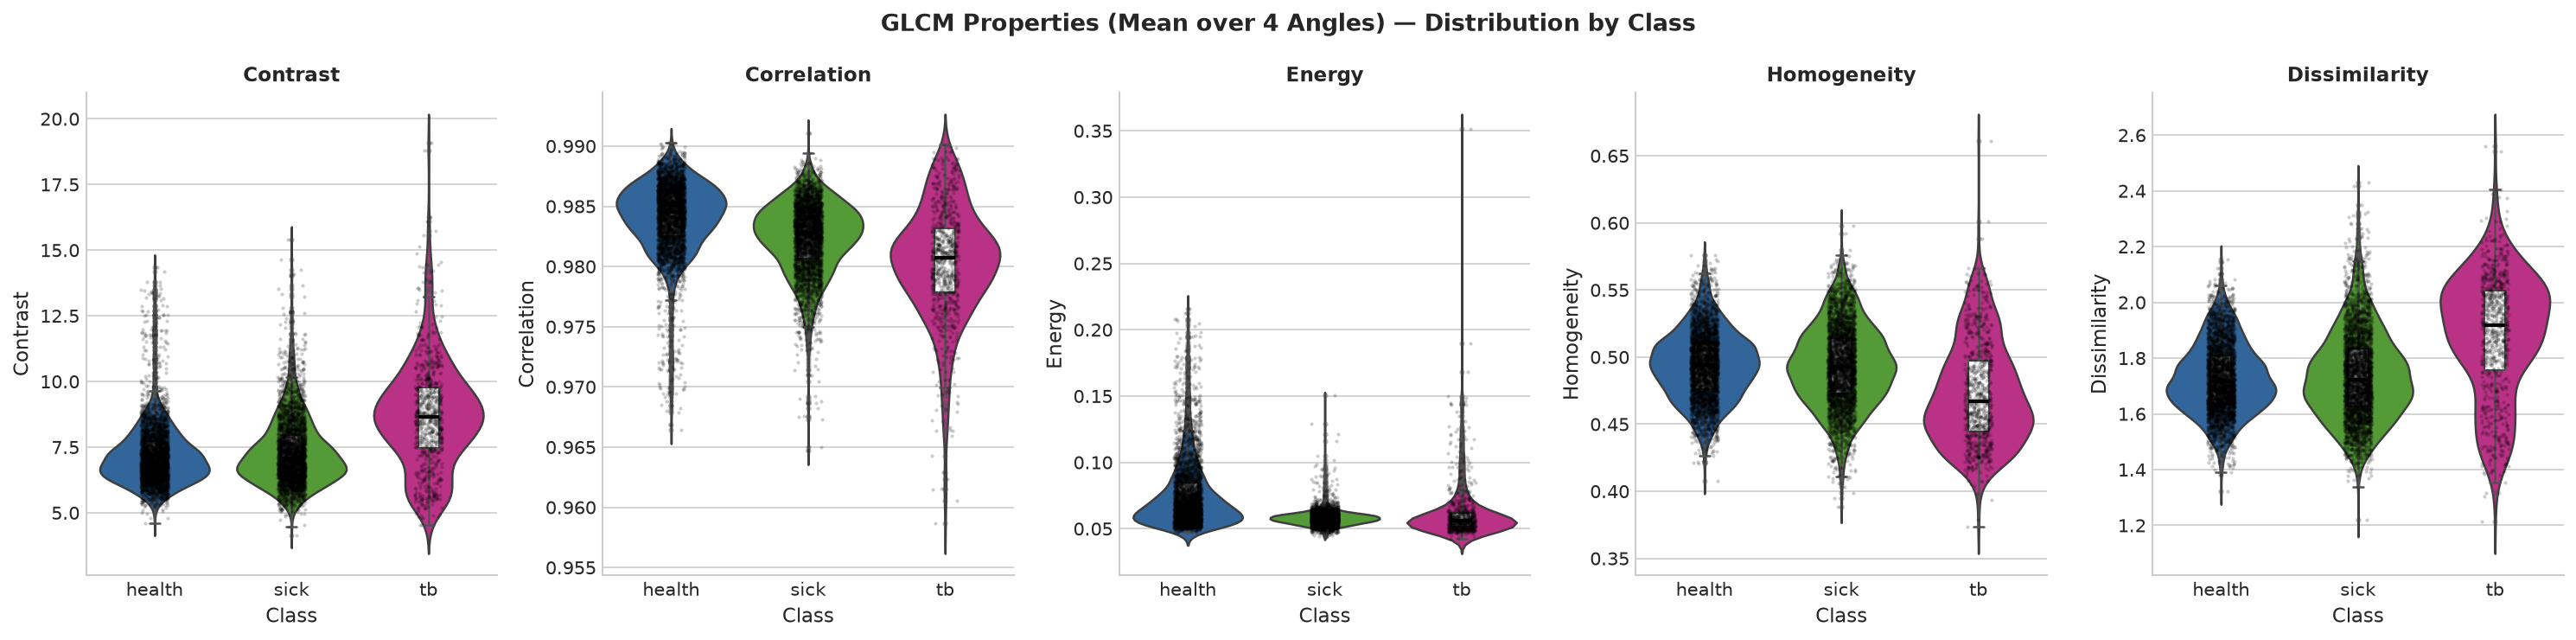

In [9]:
# Se visualizan las distribuciones de las cinco propiedades GLCM por clase.
# Si una propiedad presenta separación visual entre clases, tendrá mayor
# capacidad discriminativa en el modelo de clasificación.
# Referencia graycoprops: https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.graycoprops

plot_glcm_distributions(features_df)

## 7. Visualización del histograma LBP promedio

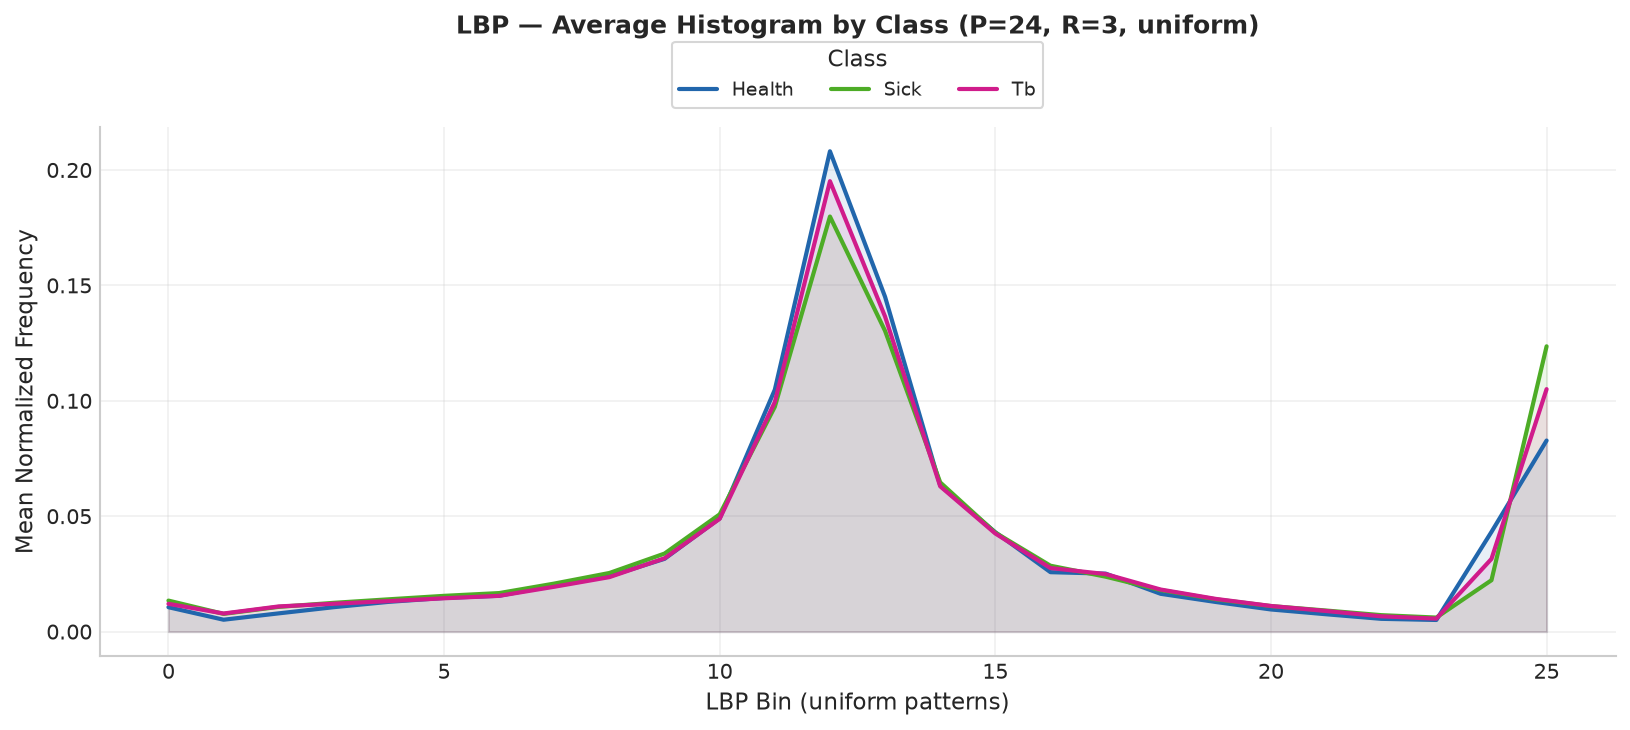

In [10]:
# Se grafica el histograma LBP promedio por clase.
# Diferencias en la distribución de bins LBP indican que las texturas locales
# difieren entre clases, lo cual es útil para la clasificación.


plot_lbp_histograms(features_df)

## 8. Estadísticas descriptivas de las features globales

In [11]:
# Se generan tablas descriptivas de las features de intensidad global por clase.
# Sirven como línea base para interpretar los resultados del modelo de clasificación.

grupos = get_feature_groups(features_df)
glob_cols = grupos['Intensidad global']

# --- Tabla 1: media por clase ---
tabla_mean = (features_df.groupby('class_name')[glob_cols].mean().round(4))
tabla_mean.index.name = 'Class'
print('Table 1 — Mean by class:')
print(tabla_mean.to_string())
print()

# --- Tabla 2: desviación estándar por clase ---
tabla_std = (features_df.groupby('class_name')[glob_cols].std().round(4))
tabla_std.index.name = 'Class'
print('Table 2 — Standard deviation by class:')
print(tabla_std.to_string())
print()

# --- Tabla 3: media ± std consolidada ---
tabla_resumen = tabla_mean.copy().astype(str)
for col in glob_cols:
    tabla_resumen[col] = tabla_mean[col].round(3).astype(str) + ' ± ' + tabla_std[col].round(3).astype(str)
tabla_resumen.index.name = 'Class'
print('Table 3 — Summary (mean ± std):')
print(tabla_resumen.to_string())

Table 1 — Mean by class:
            mean      std  contrast  entropy
Class                                       
health  124.4519  60.5129  254.9068   5.3538
sick    132.9042  57.8527  254.9374   5.4029
tb      127.5513  59.7003  254.9225   5.3964

Table 2 — Standard deviation by class:
          mean     std  contrast  entropy
Class                                    
health  5.0212  1.7594    0.2970   0.0776
sick    3.8207  1.7832    0.2477   0.0319
tb      4.2676  2.0892    0.2676   0.0712

Table 3 — Summary (mean ± std):
                   mean             std         contrast        entropy
Class                                                                  
health  124.452 ± 5.021  60.513 ± 1.759  254.907 ± 0.297  5.354 ± 0.078
sick    132.904 ± 3.821  57.853 ± 1.783  254.937 ± 0.248  5.403 ± 0.032
tb      127.551 ± 4.268    59.7 ± 2.089  254.922 ± 0.268  5.396 ± 0.071


## 10. Validación del conjunto ampliado de características

El objetivo de esta sección no es todavía seleccionar el modelo final, sino comprobar
si las nuevas características aportan **capacidad discriminativa adicional** frente al
conjunto base de 3300 features.

Se comparan tres representaciones:

1. **Base (3300):** las siete familias originales.
2. **Nuevas (899):** únicamente las cinco familias incorporadas.
3. **Ampliada (4199):** conjunto base + nuevas características.

La comparación utiliza exactamente el mismo clasificador y los mismos folds de
validación cruzada estratificada. La selección de características se ejecuta **dentro
del pipeline de cada fold**, evitando fuga de información (*data leakage*).

> Las métricas más importantes para este dataset son `balanced_accuracy` y `F1-macro`,
> porque permiten observar el comportamiento conjunto de las tres clases y no solo el
> rendimiento sobre las clases mayoritarias.


In [ ]:
# Comparación reproducible entre el conjunto base, las nuevas features y el conjunto ampliado.
# La selección de las 500 mejores variables se realiza dentro de cada fold mediante
# SelectKBest, por lo que ninguna información del fold de validación interviene en el ajuste.

from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

meta_cols = {'image_path', 'class_name', 'label'}
feature_groups = get_feature_groups(features_df)

base_group_names = [
    'Intensidad global', 'Intensidad regional', 'GLCM', 'LBP',
    'HOG', 'Gabor', 'PHOG',
]
new_group_names = [
    'Estadística avanzada', 'GLCM multiescala/regional', 'LBP multiescala',
    'Asimetría bilateral', 'GIST',
]

base_cols = [c for g in base_group_names for c in feature_groups[g]]
new_cols = [c for g in new_group_names for c in feature_groups[g]]
expanded_cols = base_cols + new_cols

assert len(base_cols) == 3300
assert len(new_cols) == 899
assert len(expanded_cols) == 4199

X_base = features_df[base_cols].replace([np.inf, -np.inf], np.nan).fillna(0)
X_new = features_df[new_cols].replace([np.inf, -np.inf], np.nan).fillna(0)
X_expanded = features_df[expanded_cols].replace([np.inf, -np.inf], np.nan).fillna(0)
y = features_df['label']

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def evaluate_representation(X, name):
    k = min(500, X.shape[1])
    pipeline = Pipeline([
        ('selector', SelectKBest(score_func=f_classif, k=k)),
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(
            max_iter=3000, class_weight='balanced', solver='lbfgs'
        )),
    ])
    scores = cross_validate(
        pipeline, X, y, cv=cv,
        scoring={
            'accuracy': 'accuracy',
            'balanced_accuracy': 'balanced_accuracy',
            'f1_macro': 'f1_macro',
            'roc_auc_ovr_macro': 'roc_auc_ovr_macro',
        },
        n_jobs=-1,
        return_train_score=False,
    )
    return {
        'Representación': name,
        'Features': X.shape[1],
        'Accuracy': scores['test_accuracy'].mean(),
        'Balanced Accuracy': scores['test_balanced_accuracy'].mean(),
        'F1-macro': scores['test_f1_macro'].mean(),
        'AUC-OVR macro': scores['test_roc_auc_ovr_macro'].mean(),
        '± F1-macro': scores['test_f1_macro'].std(),
    }

resultados_validacion = pd.DataFrame([
    evaluate_representation(X_base, 'Base'),
    evaluate_representation(X_new, 'Nuevas'),
    evaluate_representation(X_expanded, 'Ampliada'),
])

print('Comparación mediante validación cruzada estratificada (5 folds):')
print(resultados_validacion.round(4).to_string(index=False))


In [ ]:
# Cuantificación del cambio producido por las nuevas características.
# La comparación principal es Base vs. Ampliada.

base_result = resultados_validacion.iloc[0]
new_result = resultados_validacion.iloc[1]
expanded_result = resultados_validacion.iloc[2]

comparacion = pd.DataFrame({
    'Métrica': ['Accuracy', 'Balanced Accuracy', 'F1-macro', 'AUC-OVR macro'],
    'Base': [
        base_result['Accuracy'], base_result['Balanced Accuracy'],
        base_result['F1-macro'], base_result['AUC-OVR macro'],
    ],
    'Ampliada': [
        expanded_result['Accuracy'], expanded_result['Balanced Accuracy'],
        expanded_result['F1-macro'], expanded_result['AUC-OVR macro'],
    ],
})
comparacion['Cambio'] = comparacion['Ampliada'] - comparacion['Base']

print('Cambio producido por la incorporación de las 899 nuevas features:')
print(comparacion.round(4).to_string(index=False))

print()
print('Interpretación automática:')
delta_f1 = expanded_result['F1-macro'] - base_result['F1-macro']
delta_bal = expanded_result['Balanced Accuracy'] - base_result['Balanced Accuracy']

if delta_f1 > 0 and delta_bal > 0:
    print('✓ El conjunto ampliado mejora simultáneamente F1-macro y Balanced Accuracy.')
elif delta_f1 > 0 or delta_bal > 0:
    print('~ Las nuevas features aportan una mejora parcial; conviene analizar los grupos individualmente.')
else:
    print('✗ El conjunto ampliado no mejora las métricas globales con esta configuración.')

if new_result['F1-macro'] > base_result['F1-macro']:
    print('✓ El bloque de nuevas features contiene señal discriminativa adicional respecto al conjunto base.')
else:
    print('~ El bloque de nuevas features por sí solo no supera al conjunto base; esto no implica que sean inútiles al combinarse con las originales.')


In [ ]:
# Evaluación complementaria sobre un único conjunto de prueba estratificado.
# Se utiliza únicamente para observar si la mejora también se refleja en la recuperación
# (recall/sensibilidad) de cada clase.

from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_expanded, y, test_size=0.20, stratify=y, random_state=42
)

k = min(500, X_expanded.shape[1])
modelo_ampliado = Pipeline([
    ('selector', SelectKBest(score_func=f_classif, k=k)),
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        max_iter=3000, class_weight='balanced', solver='lbfgs'
    )),
])

modelo_ampliado.fit(X_train, y_train)
y_pred = modelo_ampliado.predict(X_test)

print('Reporte de clasificación — conjunto ampliado:')
print(classification_report(
    y_test,
    y_pred,
    target_names=[k for k, _ in sorted(LABEL_MAP.items(), key=lambda item: item[1])],
    digits=4,
    zero_division=0,
))


### Criterio de decisión

La ampliación se considera prometedora si, manteniendo el mismo procedimiento de
validación, el conjunto de **4199 features** obtiene una mejora consistente sobre los
**3300 features base**, especialmente en `F1-macro` y `Balanced Accuracy`.

La tabla también permite distinguir dos situaciones:

- Si **Nuevas > Base**, las cinco familias nuevas contienen señal discriminativa relevante.
- Si **Ampliada > Base** pero **Nuevas ≤ Base**, las nuevas características pueden estar
  aportando información complementaria que funciona en combinación con HOG, PHOG,
  GLCM, LBP o Gabor.

Esta validación no demuestra que las 899 variables deban conservarse todas. El siguiente
paso debe ser analizar redundancia, correlación, importancia y selección de características
antes del entrenamiento definitivo de los modelos tradicionales.


## 11. Exportación a CSV

In [12]:
# Se reordena el DataFrame para que las columnas de metadatos queden primero
# y se exporta a CSV en la raíz del proyecto.
# Este archivo es la entrada para la siguiente etapa del pipeline (modelado ML).

meta_cols = ['image_path', 'class_name', 'label']
feat_cols = [c for c in features_df.columns if c not in meta_cols]

features_df = features_df[meta_cols + feat_cols]
features_df.to_csv(OUTPUT_CSV, index=False)

print(f'Guardado en : {OUTPUT_CSV}')
print(f'Shape       : {features_df.shape}')
print(f'Tamaño      : {os.path.getsize(OUTPUT_CSV) / 1024 / 1024:.2f} MB')
print()
print('Primeras 3 filas (columnas de metadatos + primeras 5 features):')
print(features_df[meta_cols + feat_cols[:5]].head(3).to_string(index=False))

Guardado en : ..\data\features_tbx11k.csv
Shape       : (8400, 3303)
Tamaño      : 520.70 MB

Primeras 3 filas (columnas de metadatos + primeras 5 features):
                                                                      image_path class_name  label       mean       std  contrast  entropy    SI_mean
c:\Users\estra\Desktop\Tuberculosis\cad-tbx11k\data\TBX11K\imgs\health\h0001.png     health      0 122.254684 60.721951     255.0 5.344006 115.871820
c:\Users\estra\Desktop\Tuberculosis\cad-tbx11k\data\TBX11K\imgs\health\h0003.png     health      0 127.705917 56.183601     255.0 5.344041 118.011900
c:\Users\estra\Desktop\Tuberculosis\cad-tbx11k\data\TBX11K\imgs\health\h0004.png     health      0 124.981613 56.692275     255.0 5.310210 109.403434


## 12. Conclusiones

El conjunto ampliado incorpora 899 características adicionales orientadas a representar
información que los descriptores originales no capturan explícitamente: forma avanzada
de la distribución de intensidades, textura a múltiples escalas, microtexturas
complementarias, asimetría entre hemitórax y contexto espacial global.

La utilidad de esta ampliación debe establecerse mediante la comparación Base vs.
Ampliada de la sección de validación. Una mejora en `F1-macro` y `Balanced Accuracy`
indicaría que el nuevo conjunto ofrece mayor capacidad de separación entre `health`,
`sick` y `tb`. Si la mejora es pequeña o inexistente, las características deberán
analizarse y reducirse antes del entrenamiento final, en lugar de conservarlas
únicamente por aumentar la dimensionalidad.


## 13. Próximas etapas

```text
features_tbx11k.csv
       │
       ▼
Análisis de características
(correlación, redundancia, importancia y distribución)
       │
       ▼
Selección / reducción de dimensionalidad
       │
       ▼
Entrenamiento de modelos de ML tradicional
       │
       ▼
Evaluación final
(sensibilidad, especificidad, F1 por clase, AUC)
```

La validación incluida en este notebook funciona como una **comparación inicial del
espacio de características**. La evaluación definitiva del sistema debe realizarse
posteriormente con el protocolo experimental completo y sin fuga de información.
